In [34]:
import numpy as np
import matplotlib.pyplot as plt

from linsolver import (
    Equation,
    solveGaussWithPivoting,
    solveLUDecomposition,
    solveJacobiMethod,
    solveSeidelMethod,
    solveSOR,
    solveGradientDescent,
    solveMinimalResidual,
    solveCG,
    solveBiCGSTAB,
)

## Система из пункта «и»

In [35]:
n = 100
a = 100.0
indices = np.arange(1.0, n + 1.0)

A = np.zeros((n, n))
for row in range(n):
    i = row + 1
    A[row, row] = a
    A[row, :row] = i / indices[:row]
    if row + 1 < n:
        A[row, row + 1] = i / (i + 1)

b = indices.copy()

def make_equation():
    return Equation(A.copy(), b.copy())

## Прямые методы

In [36]:
np.set_printoptions(precision=8, suppress=True, linewidth=120)

x_gauss = solveGaussWithPivoting(make_equation())
x_lu = solveLUDecomposition(make_equation())

print("Решение методом Гаусса:")
print(x_gauss)
print(f"Невязка Гаусса: {np.linalg.norm(A @ x_gauss - b):.3e}")
print(f"Невязка LU:     {np.linalg.norm(A @ x_lu - b):.3e}")
print(f"||x_LU - x_Gauss||₂ = {np.linalg.norm(x_lu - x_gauss):.3e}")

Решение методом Гаусса:
[0.00990196 0.01960782 0.0291205  0.03844287 0.04757776 0.05652798 0.06529628 0.07388539 0.08229801 0.09053677
 0.09860431 0.1065032  0.11423599 0.1218052  0.12921332 0.13646277 0.143556   0.15049536 0.15728323 0.16392191
 0.1704137  0.17676086 0.1829656  0.18903014 0.19495664 0.20074723 0.20640403 0.21192913 0.21732456 0.22259237
 0.22773454 0.23275306 0.23764986 0.24242686 0.24708596 0.25162902 0.25605788 0.26037436 0.26458025 0.26867732
 0.27266731 0.27655194 0.28033291 0.28401188 0.2875905  0.29107041 0.2944532  0.29774046 0.30093376 0.30403461
 0.30704456 0.30996508 0.31279766 0.31554375 0.31820479 0.3207822  0.32327735 0.32569165 0.32802643 0.33028305
 0.33246281 0.33456701 0.33659695 0.33855389 0.34043906 0.34225371 0.34399904 0.34567625 0.34728652 0.348831
 0.35031085 0.35172718 0.35308112 0.35437376 0.35560618 0.35677945 0.35789461 0.35895271 0.35995477 0.36090178
 0.36179475 0.36263464 0.36342243 0.36415906 0.36484548 0.36548259 0.36607131 0.36661254 0

## Итерационные методы

В функциях задаётся число итераций, а необязательный `callback(k, x_k)` вызывается для начального приближения ($k=0$) и после каждого шага. Так решение и вся история невязки получаются за один запуск метода.

In [37]:
iteration_count = 30

def make_residual_callback():
    iterations = []
    residuals = []

    def callback(k, x_k):
        iterations.append(k)
        residuals.append(np.linalg.norm(A @ x_k - b))

    return callback, iterations, residuals

method_runners = {
    "Якоби": lambda callback: solveJacobiMethod(make_equation(), iteration_count, callback),
    "Зейдель": lambda callback: solveSeidelMethod(make_equation(), iteration_count, callback),
    "SOR, omega=1.1": lambda callback: solveSOR(make_equation(), 1.1, iteration_count, callback),
    "Градиентный спуск": lambda callback: solveGradientDescent(make_equation(), iteration_count, callback),
    "Минимальные невязки": lambda callback: solveMinimalResidual(make_equation(), iteration_count, callback),
    "Сопряжённые градиенты": lambda callback: solveCG(make_equation(), iteration_count, callback),
    "BiCGSTAB": lambda callback: solveBiCGSTAB(make_equation(), iteration_count, callback),
}

iterative_solutions = {}
histories = {}
for name, run_method in method_runners.items():
    callback, iterations, residuals = make_residual_callback()
    iterative_solutions[name] = run_method(callback)
    histories[name] = (np.asarray(iterations), np.asarray(residuals))

    x = iterative_solutions[name]
    residual = np.linalg.norm(A @ x - b)
    difference = np.linalg.norm(x - x_gauss)
    print(f"{name:25s}: ||Ax-b||₂={residual:.3e}, ||x-x_Gauss||₂={difference:.3e}")

Якоби                    : ||Ax-b||₂=5.454e-14, ||x-x_Gauss||₂=1.615e-15
Зейдель                  : ||Ax-b||₂=5.454e-14, ||x-x_Gauss||₂=1.615e-15
SOR, omega=1.1           : ||Ax-b||₂=5.454e-14, ||x-x_Gauss||₂=1.615e-15
Градиентный спуск        : ||Ax-b||₂=2.738e-13, ||x-x_Gauss||₂=2.735e-15
Минимальные невязки      : ||Ax-b||₂=3.900e+02, ||x-x_Gauss||₂=7.885e+00
Сопряжённые градиенты    : ||Ax-b||₂=5.532e+07, ||x-x_Gauss||₂=1.916e+05
BiCGSTAB                 : ||Ax-b||₂=6.744e-13, ||x-x_Gauss||₂=6.685e-15


## Зависимость невязки от номера итерации

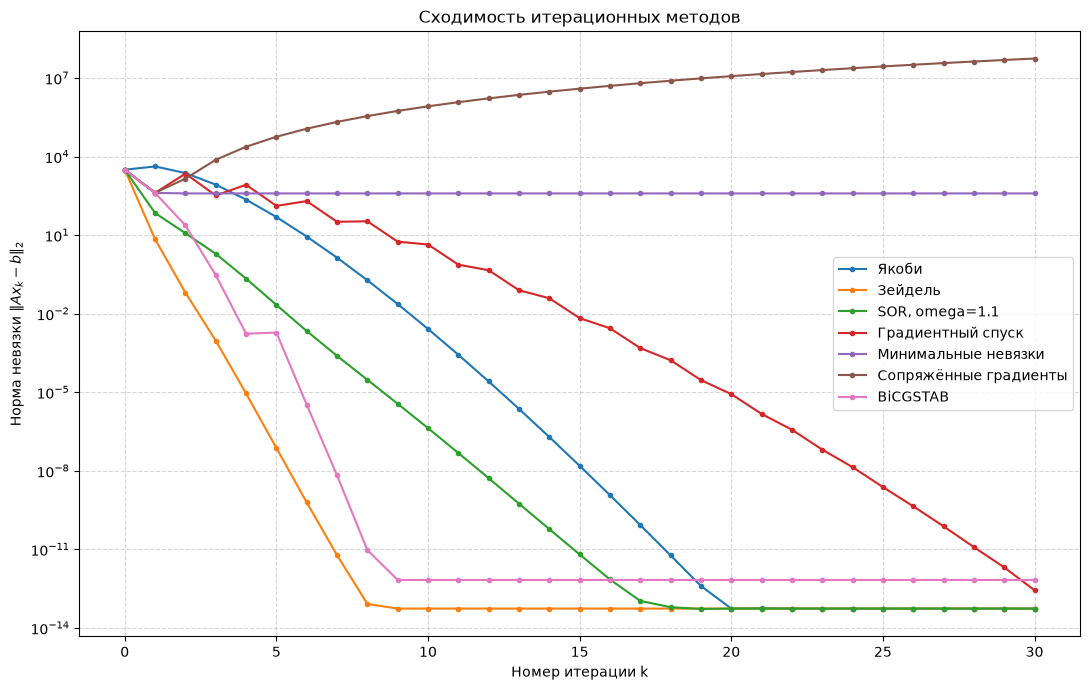

In [38]:
plt.figure(figsize=(11, 7))
for name, (iterations, residuals) in histories.items():
    # Защита логарифмического масштаба от log(0) для точного нуля.
    residuals_for_plot = np.maximum(residuals, np.finfo(float).tiny)
    plt.semilogy(iterations, residuals_for_plot, marker=".", label=name)

plt.xlabel("Номер итерации k")
plt.ylabel(r"Норма невязки $\|Ax_k-b\|_2$")
plt.title("Сходимость итерационных методов")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Обсуждение

## Метод споряженных градиентов

Логично, что он разошёлся, ведь метод сопряженных градиентов строится для симметрической положительно определенной матрицы, а матрица в задании не такая.

## Стабилизированный метод бисопряжённых градиентов

Этот метод также не сошёлся, поскольку матрица не является симметрической и положительно определенной. В ортогонализации $r_k$ становится практически ортогонален $Ar_k$, поэтому числитель при вычислении $\alpha_k$ стремится к нулю и метод застревает.